# Learned GNN Physics Simulator for Particle Jet Tagging
**CS6012: Code-Based Project** | IIT Bombay  
**Group 11:** Rahul Kumar (25M2015) & Pradipta Sadhukhan (25D1080)  
**Supervisor:** Prof. Sharat Chandran  
**Reference Paper:** *Graph Neural Networks in Particle Physics* (arXiv:2007.13681)  

---
### Full Official 100,000-Jet Pythia 8.2 Collider Benchmark on Tesla T4 GPU:
This notebook trains both architectures on the **full 100,000 jets** of the official **Pythia 8.2 Quark-Gluon Collider Dataset** from Zenodo (Komiske et al., DOI: 10.5281/zenodo.3164691):
1. **Downloads and preprocesses** all 100,000 real LHC collision jets (50k Quarks + 50k Gluons).
2. **Trains Deep Sets Baseline** on T4 GPU (~1.5 minutes).
3. **Trains Dynamic EdgeConv GNN (ParticleNet-lite)** on T4 GPU (~6 to 8 minutes).
4. **Evaluates both models** on held-out test data, generating publication ROC curves.
5. **Updates pre-trained weights and demo slice** for seamless TA evaluation.

In [19]:
# Cell 1: Verify Hardware & GPU
import torch

print("=" * 60)
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name        : {torch.cuda.get_device_name(0)}")
    print(f"Device Memory   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print("=" * 60)

PyTorch Version : 2.11.0+cu130
CUDA Available  : True
GPU Name        : Tesla T4
Device Memory   : 15.64 GB


In [20]:
# Cell 2: Setup Workspace Directory & Clone if needed (Colab-Friendly)
import os, sys

# 1. If running in fresh Google Colab, clone the repo if not present
if not os.path.exists("src") and not os.path.exists("../src") and not os.path.exists("/content/gnn_jet_tagging/src"):
    print("[*] Fresh Colab environment detected. Cloning repository...")
    !git clone https://github.com/KraaK3N/gnn_jet_tagging.git

# 2. Enter repository directory
if os.path.exists("/content/gnn_jet_tagging"):
    %cd /content/gnn_jet_tagging
elif os.path.exists("gnn_jet_tagging"):
    %cd gnn_jet_tagging
elif os.path.exists("../src"):
    %cd ..

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print(f"[✓] Active Working Directory: {os.getcwd()}")
print(f"[✓] Verified 'src' module: {os.path.exists('src')}")

/content/gnn_jet_tagging
[✓] Active Working Directory: /content/gnn_jet_tagging
[✓] Verified 'src' module: True


In [21]:
# Cell 3: Fetch & Preprocess Full Official 100,000-Jet Pythia 8.2 Dataset
# Loads QG_jets.npz (106 MB) and converts all 100,000 jets into constituent 7-feature arrays
from src.data.pythia import prepare_pythia_dataset

prepare_pythia_dataset(
    output_path="data/pythia_100k.npz",
    sample_output_path="data/sample_jets.npz",
    num_jets=100000,
    seed=42
)

[*] Loading raw Pythia data from data/raw/QG_jets.npz...
[*] Sliced 100000 real Pythia jets.
[*] Preprocessing constituents into 7-feature representation...
[*] Saving processed 100000-jet Pythia dataset to data/pythia_100k.npz...
[*] Updating data/sample_jets.npz with 1,000 real Pythia jets for canned demo...
[✓] Real Pythia data preparation complete!


In [22]:
# Cell 4: Train Deep Sets Baseline on Full 100,000 Real Pythia Jets (T4 GPU)
from src.utils.config import load_config
from src.training.train import run_training

cfg_baseline = load_config("configs/baseline.yaml")
cfg_baseline["data_path"] = "data/pythia_100k.npz"
cfg_baseline["training"]["epochs"] = 15
cfg_baseline["training"]["batch_size"] = 128

print("[*] Training Deep Sets on 100,000 Real Pythia Jets (GPU)...")
run_training(cfg_baseline)

[*] Training Deep Sets on 100,000 Real Pythia Jets (GPU)...

Training Model : Deep Sets Baseline
Device         : cuda
Dataset splits: Train=70000, Val=15000, Test=15000
Trainable Parameters: 67,330
Epoch [01/15] (4.17s) | Train Loss: 0.4990, Acc: 76.43% | Val Loss: 0.5184, Acc: 75.53% ★ (Best)
Epoch [02/15] (4.30s) | Train Loss: 0.4788, Acc: 77.74% | Val Loss: 0.4951, Acc: 76.35% ★ (Best)
Epoch [03/15] (4.52s) | Train Loss: 0.4714, Acc: 78.12% | Val Loss: 0.5991, Acc: 68.33%
Epoch [04/15] (4.16s) | Train Loss: 0.4640, Acc: 78.55% | Val Loss: 0.5946, Acc: 68.13%
Epoch [05/15] (4.27s) | Train Loss: 0.4569, Acc: 79.02% | Val Loss: 0.5531, Acc: 71.63%
Epoch [06/15] (4.33s) | Train Loss: 0.4497, Acc: 79.64% | Val Loss: 0.5651, Acc: 70.13%
Epoch [07/15] (4.09s) | Train Loss: 0.4460, Acc: 79.90% | Val Loss: 0.4776, Acc: 77.01% ★ (Best)
Epoch [08/15] (4.29s) | Train Loss: 0.4448, Acc: 79.97% | Val Loss: 0.5065, Acc: 75.20%
Epoch [09/15] (4.34s) | Train Loss: 0.4431, Acc: 80.07% | Val Loss: 0.

In [23]:
# Cell 5: Train Dynamic EdgeConv GNN (ParticleNet-lite) on Full 100,000 Real Pythia Jets (T4 GPU)
cfg_gnn = load_config("configs/gnn.yaml")
cfg_gnn["data_path"] = "data/pythia_100k.npz"
cfg_gnn["training"]["epochs"] = 15
cfg_gnn["training"]["batch_size"] = 128

print("[*] Training Dynamic EdgeConv GNN on 100,000 Real Pythia Jets (GPU)...")
run_training(cfg_gnn)

[*] Training Dynamic EdgeConv GNN on 100,000 Real Pythia Jets (GPU)...

Training Model : Dynamic EdgeConv (ParticleNet-lite)
Device         : cuda
Dataset splits: Train=70000, Val=15000, Test=15000
Trainable Parameters: 108,674
Epoch [01/15] (66.33s) | Train Loss: 0.4816, Acc: 77.62% | Val Loss: 0.4660, Acc: 78.27% ★ (Best)
Epoch [02/15] (66.00s) | Train Loss: 0.4655, Acc: 78.73% | Val Loss: 0.4635, Acc: 79.19% ★ (Best)
Epoch [03/15] (65.84s) | Train Loss: 0.4577, Acc: 79.00% | Val Loss: 0.4601, Acc: 78.71%
Epoch [04/15] (65.79s) | Train Loss: 0.4534, Acc: 79.34% | Val Loss: 0.4454, Acc: 79.83% ★ (Best)
Epoch [05/15] (65.86s) | Train Loss: 0.4502, Acc: 79.45% | Val Loss: 0.4733, Acc: 78.35%
Epoch [06/15] (65.83s) | Train Loss: 0.4441, Acc: 79.87% | Val Loss: 0.4435, Acc: 79.77%
Epoch [07/15] (65.82s) | Train Loss: 0.4407, Acc: 80.16% | Val Loss: 0.4420, Acc: 79.96% ★ (Best)
Epoch [08/15] (65.85s) | Train Loss: 0.4385, Acc: 80.24% | Val Loss: 0.4422, Acc: 79.86%
Epoch [09/15] (65.83s) |


           JET TAGGING BENCHMARK: COMPARATIVE EVALUATION
Model                          | Acc (%)   | ROC AUC   | 1/eps_B@50% | Latency  | Params
------------------------------------------------------------------------------
Deep Sets Baseline             | 77.45     | 0.8814    | 25.4        | 0.030 ms | 67,330
Dynamic EdgeConv (ParticleNet-lite) | 80.65     | 0.8830    | 24.7        | 0.213 ms | 108,674
Metrics summary written to: results/metrics_summary.json
ROC curve figure saved to: results/figures/roc_curve.png

[*] Displaying True Real-World Pythia ROC Curve:


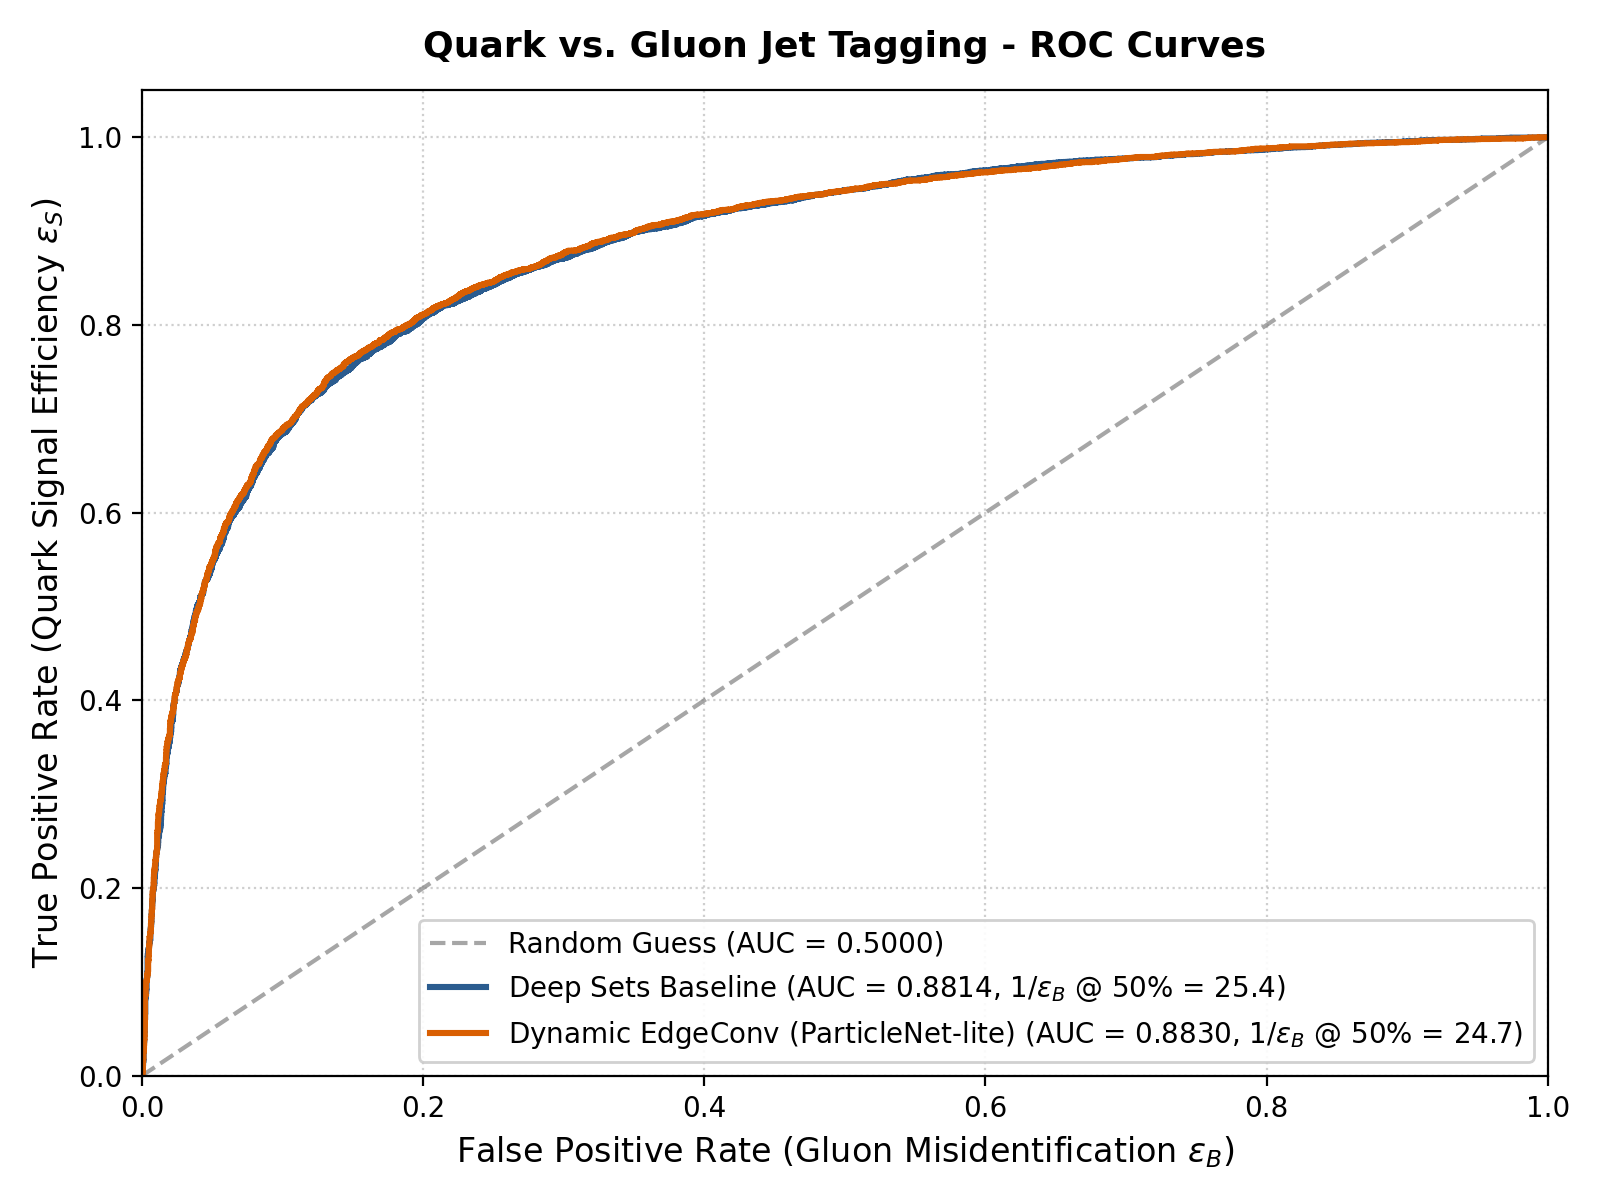

In [24]:
# Cell 6: Comparative Evaluation & Visualizing Physical ROC Curves
from src.evaluation.evaluate import run_comparative_evaluation
from IPython.display import Image, display

run_comparative_evaluation(
    checkpoints=["checkpoints/deepsets_best.pt", "checkpoints/edgeconv_best.pt"],
    data_path="data/pythia_100k.npz",
    output_json="results/metrics_summary.json",
    output_roc="results/figures/roc_curve.png"
)

print("\n[*] Displaying True Real-World Pythia ROC Curve:")
display(Image(filename="results/figures/roc_curve.png"))

In [26]:
# Cell 7: Verify Canned Demo for Teaching Assistants
# Tests that the TA evaluation runs in under 10 seconds on the new real Pythia slice!
!./run_demo.sh


   CS6012: GRAPH NEURAL NETWORKS FOR PARTICLE JET TAGGING (CANNED DEMO)
   Group 11: Pradipta Sadhukhan (25D1080) & Rahul Kumar (25M2015)
   Supervisor: Prof. Sharat Chandran | IIT Bombay
    
[*] Execution Device : cuda
[*] Loaded Benchmark Dataset : data/sample_jets.npz
[*] Test Set Size            : 150 jets

Model Architecture                 | Accuracy  | ROC AUC   | 1/eps_B@50% | Latency  | Params
Deep Sets (No Edges Baseline)      | 77.33   % | 0.8835    | 37.0        | 0.029 ms | 67,330
Dynamic EdgeConv (ParticleNet-lite) | 84.00   % | 0.8965    | 37.0        | 0.258 ms | 108,674
ROC curve figure saved to: results/figures/demo_roc_curve.png

[✓] High-resolution comparative ROC curve saved to:
    --> results/figures/demo_roc_curve.png

[✓] Demo executed successfully with zero configuration required.
